In [61]:
import numpy as np

In [62]:
m = np.array([[1,2,3],
            [4,5,6]])
mT = m.T

print("M Transposed: \n", mT)

M Transposed: 
 [[1 4]
 [2 5]
 [3 6]]


In [63]:
v = np.array([1,2])
v2 = np.array([3,4])

vdot = np.dot(v,v2)

print("Vector Dot Product: \n",vdot)

Vector Dot Product: 
 11


In [64]:
# Given the following dataset:
# import numpy as npimport pandas as pdimport matplotlib.pyplot as pltdata = pd.DataFrame({    "study_hours": [1, 2, 3, 4, 5, 6, 7, 8],    "practice_hours": [2, 3, 2, 5, 4, 7, 6, 9],    "exam_score": [25, 30, 35, 45, 48, 60, 65, 80]})


# Tasks
# Perform matrix and vector operations on the dataset.
# Implement gradient descent and visualize cost reduction.
# Apply PCA to reduce the features and visualize the results.

In [65]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.DataFrame({
    "study_hours": [1, 2, 3, 4, 5, 6, 7, 8],
    "practice_hours": [2, 3, 2, 5, 4, 7, 6, 9],
    "exam_score": [25, 30, 35, 45, 48, 60, 65, 80]
})

data

,study_hours,practice_hours,exam_score
0,1,2,25
1,2,3,30
2,3,2,35
3,4,5,45
4,5,4,48
5,6,7,60
6,7,6,65
7,8,9,80


In [66]:
X = data[["study_hours", "practice_hours"]].values

print("Transpose:\n", X.T)

Transpose:
 [[1 2 3 4 5 6 7 8]
 [2 3 2 5 4 7 6 9]]


In [67]:
print("Addition:\n", X + X)

Addition:
 [[ 2  4]
 [ 4  6]
 [ 6  4]
 [ 8 10]
 [10  8]
 [12 14]
 [14 12]
 [16 18]]


In [68]:
print("Subtraction:\n", X - X)

Subtraction:
 [[0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]
 [0 0]]


In [69]:
print("Scalar Multiplication:\n", X * 2)

Scalar Multiplication:
 [[ 2  4]
 [ 4  6]
 [ 6  4]
 [ 8 10]
 [10  8]
 [12 14]
 [14 12]
 [16 18]]


In [70]:
print("Matrix Multiplication:\n", X.T @ X)

Matrix Multiplication:
 [[204 210]
 [210 224]]


In [71]:
print("Rank:", np.linalg.matrix_rank(X))

Rank: 2


In [72]:
v1 = X[0]
v2 = X[1]

print("Magnitude:", np.linalg.norm(v1))
print("Direction:", np.arctan2(v1[1], v1[0]))

print("Dot Product:", np.dot(v1, v2))
print("Cosine Similarity:", np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)))

print("Euclidean Distance:", np.linalg.norm(v1 - v2))
print("Manhattan Distance:", np.sum(np.abs(v1 - v2)))

Magnitude: 2.23606797749979
Direction: 1.1071487177940904
Dot Product: 8
Cosine Similarity: 0.9922778767136677
Euclidean Distance: 1.4142135623730951
Manhattan Distance: 2


In [73]:
print("Dot Product:", np.dot(v1, v2))
print("Cosine Similarity:", np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)))

Dot Product: 8
Cosine Similarity: 0.9922778767136677


In [74]:
print("Euclidean Distance:", np.linalg.norm(v1 - v2))
print("Manhattan Distance:", np.sum(np.abs(v1 - v2)))

Euclidean Distance: 1.4142135623730951
Manhattan Distance: 2


In [75]:
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)

X_gd = np.c_[np.ones(len(X)), X_scaled]

weights = np.zeros(3)
learning_rate = 0.01
cost_history = []

for i in range(1000):
    predictions = X_gd @ weights
    error = predictions - y

    gradient = (2 / len(y)) * (X_gd.T @ error)
    weights -= learning_rate * gradient

    cost = np.mean(error ** 2)
    cost_history.append(cost)

print("Final Weights:", weights)
print("Final Cost:", cost_history[-1])

Final Weights: [48.49999992 11.64452886  6.25688576]
Final Cost: 2.5186227347966987


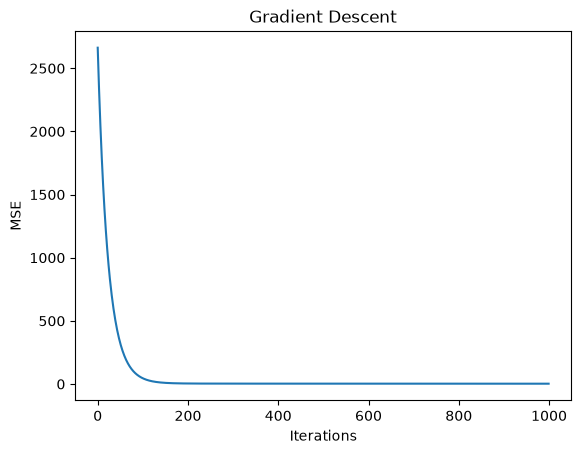

In [76]:
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("MSE")
plt.title("Gradient Descent")
plt.show()